In [1]:
import pandas as pd

# URL of the raw CSV file on GitHub
# Note: Replacing 'github.com' with 'raw.githubusercontent.com' and removing '/blob' to get the raw file content
csv_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/refs/heads/data-snapshots/data/live_snapshots/20261030_1324/skills.csv'

try:
    skills  = pd.read_csv(csv_url)
    print("DataFrame loaded successfully!")
except Exception as e:
    print(f"Error loading CSV directly: {e}")
    print("Attempting to load via requests...")
    import requests
    import io
    response = requests.get(csv_url)
    skills = pd.read_csv(io.StringIO(response.text))

DataFrame loaded successfully!


In [2]:
import pandas as pd

vacancies_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/refs/heads/data-snapshots/data/live_snapshots/20261030_1324/shown.csv'

try:
    vacancies = pd.read_csv(vacancies_url)
    print("Vacancies DataFrame loaded successfully!")
except Exception as e:
    import requests
    import io
    print(f"Error loading via pandas directly: {e}. Trying fallback with requests...")
    response = requests.get(vacancies_url)
    vacancies = pd.read_csv(io.StringIO(response.text))

# Join the two DataFrames on 'vacancy_id'
skills_flat = pd.merge(skills, vacancies, on='vacancy_id', how='inner')

print(f"Skills shape: {skills.shape}")
print(f"Vacancies shape: {vacancies.shape}")
print(f"Merged flat DataFrame shape: {skills_flat.shape}")
display(skills_flat.head())

Vacancies DataFrame loaded successfully!
Skills shape: (1512, 6)
Vacancies shape: (67, 29)
Merged flat DataFrame shape: (307, 34)


,run_id_x,vacancy_id,skill,strength,confidence,description_coverage_x,run_id_y,observation_id,source,source_id,...,description_coverage_y,collected_at,link,outcome,outcome_note,eligibility_reason,duplicate_of,duplicate_source,search_term,search_location
0,20261030T131438880602Z,reed:57250713,dashboards_reporting,unclear,stated,full,20261030T131438880602Z,obs-00006192,reed,57250713,...,full,2026-10-30T13:22:01+00:00,https://www.reed.co.uk/jobs/information-analys...,shown,NaN,NaN,NaN,NaN,data analyst,Shrewsbury
1,20261030T131438880602Z,reed:57250713,data_ethics_gdpr,unclear,stated,full,20261030T131438880602Z,obs-00006192,reed,57250713,...,full,2026-10-30T13:22:01+00:00,https://www.reed.co.uk/jobs/information-analys...,shown,NaN,NaN,NaN,NaN,data analyst,Shrewsbury
2,20261030T131438880602Z,reed:57250713,databases,essential,stated,full,20261030T131438880602Z,obs-00006192,reed,57250713,...,full,2026-10-30T13:22:01+00:00,https://www.reed.co.uk/jobs/information-analys...,shown,NaN,NaN,NaN,NaN,data analyst,Shrewsbury
3,20261030T131438880602Z,reed:57250713,sql,essential,stated,full,20261030T131438880602Z,obs-00006192,reed,57250713,...,full,2026-10-30T13:22:01+00:00,https://www.reed.co.uk/jobs/information-analys...,shown,NaN,NaN,NaN,NaN,data analyst,Shrewsbury
4,20261030T131438880602Z,reed:57382099,dashboards_reporting,essential,stated,full,20261030T131438880602Z,obs-00000006,reed,57382099,...,full,2026-10-30T13:20:51+00:00,https://www.reed.co.uk/jobs/data-analyst/57382099,shown,NaN,NaN,NaN,NaN,data analyst,Birmingham


In [3]:
# Display the first 5 rows and the dataframe's info
display(skills.head())
print("\nDataFrame Info:")
print("Shape:", skills.shape)
print("Columns:", skills.columns.tolist())
skills.info()
print(skills.isna().sum())

,run_id,vacancy_id,skill,strength,confidence,description_coverage
0,20261030T131438880602Z,greenhouse:gymshark-4863068101,crm_systems,desirable,stated,full
1,20261030T131438880602Z,greenhouse:gymshark-4958803101,excel,essential,stated,full
2,20261030T131438880602Z,greenhouse:gymshark-4959277101,data_analysis,essential,stated,full
3,20261030T131438880602Z,greenhouse:gymshark-4959277101,data_cleaning,unclear,stated,full
4,20261030T131438880602Z,greenhouse:gymshark-4959277101,erp_systems,desirable,stated,full



DataFrame Info:
Shape: (1512, 6)
Columns: ['run_id', 'vacancy_id', 'skill', 'strength', 'confidence', 'description_coverage']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1512 entries, 0 to 1511
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   run_id                1512 non-null   object
 1   vacancy_id            1512 non-null   object
 2   skill                 1512 non-null   object
 3   strength              1512 non-null   object
 4   confidence            1512 non-null   object
 5   description_coverage  1512 non-null   object
dtypes: object(6)
memory usage: 71.0+ KB
run_id                  0
vacancy_id              0
skill                   0
strength                0
confidence              0
description_coverage    0
dtype: int64


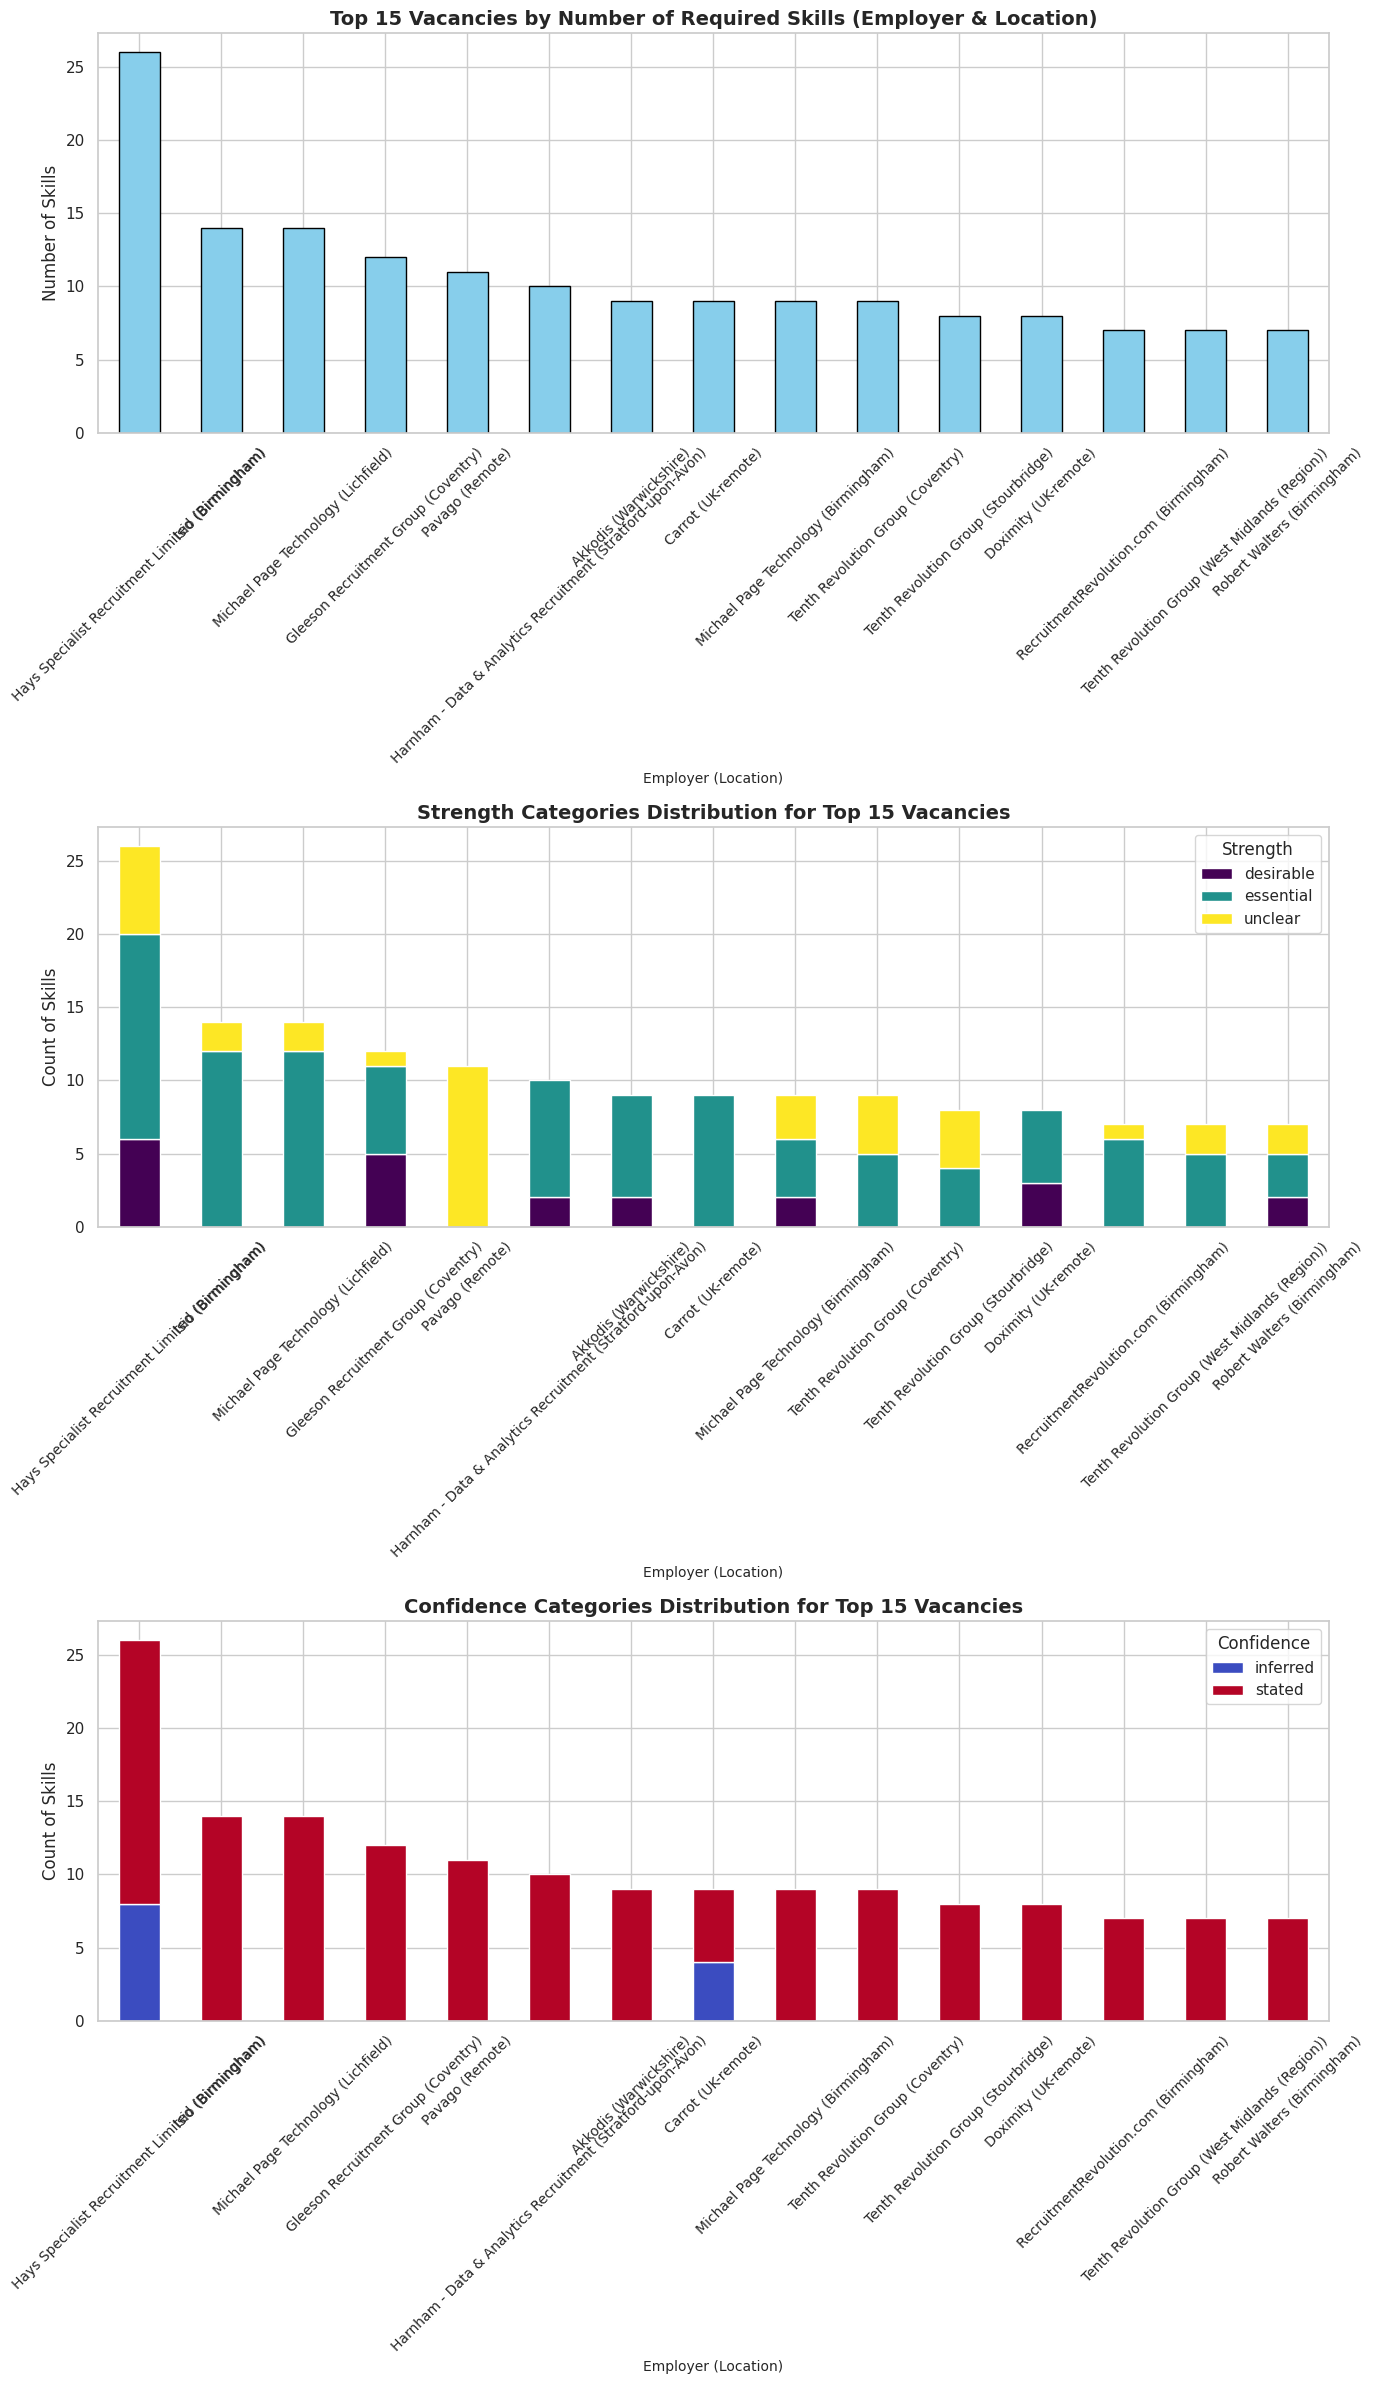

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set plotting style
sns.set_theme(style="whitegrid")

# Prepare readable identifier incorporating both Employer and Location
# Some records might have NaN values, so we handle them cleanly
skills_flat['employer_clean'] = skills_flat['employer'].fillna('Unknown Employer')
skills_flat['location_clean'] = skills_flat['location_text'].fillna('Unknown Location')
skills_flat['employer_location'] = skills_flat['employer_clean'] + ' (' + skills_flat['location_clean'] + ')'

# 1. Calculate basic aggregates per vacancy to identify the top 15
vacancy_skill_counts = skills_flat.groupby('employer_location')['skill'].count().sort_values(ascending=False)
top_vacancies_labels = vacancy_skill_counts.head(15).index

# Filter the flat dataframe to include only the top 15
skills_flat_top15 = skills_flat[skills_flat['employer_location'].isin(top_vacancies_labels)]

# 2. Prepare aggregated data for categorical columns 'strength' and 'confidence'
strength_by_vacancy = pd.crosstab(skills_flat_top15['employer_location'], skills_flat_top15['strength']).loc[top_vacancies_labels]
confidence_by_vacancy = pd.crosstab(skills_flat_top15['employer_location'], skills_flat_top15['confidence']).loc[top_vacancies_labels]

# Create a multi-plot figure
fig, axes = plt.subplots(3, 1, figsize=(14, 24))

# Plot 1: Number of skills per Employer / Location (Top 15)
vacancy_skill_counts.head(15).plot(kind='bar', ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Top 15 Vacancies by Number of Required Skills (Employer & Location)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Skills', fontsize=12)
axes[0].set_xlabel('Employer (Location)', fontsize=10)
axes[0].tick_params(axis='x', rotation=45, labelsize=10)

# Plot 2: Strength distribution per Employer / Location (Top 15)
strength_by_vacancy.plot(kind='bar', stacked=True, ax=axes[1], colormap='viridis')
axes[1].set_title('Strength Categories Distribution for Top 15 Vacancies', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Count of Skills', fontsize=12)
axes[1].set_xlabel('Employer (Location)', fontsize=10)
axes[1].tick_params(axis='x', rotation=45, labelsize=10)
axes[1].legend(title='Strength')

# Plot 3: Confidence distribution per Employer / Location (Top 15)
confidence_by_vacancy.plot(kind='bar', stacked=True, ax=axes[2], colormap='coolwarm')
axes[2].set_title('Confidence Categories Distribution for Top 15 Vacancies', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Count of Skills', fontsize=12)
axes[2].set_xlabel('Employer (Location)', fontsize=10)
axes[2].tick_params(axis='x', rotation=45, labelsize=10)
axes[2].legend(title='Confidence')

plt.tight_layout()
plt.show()

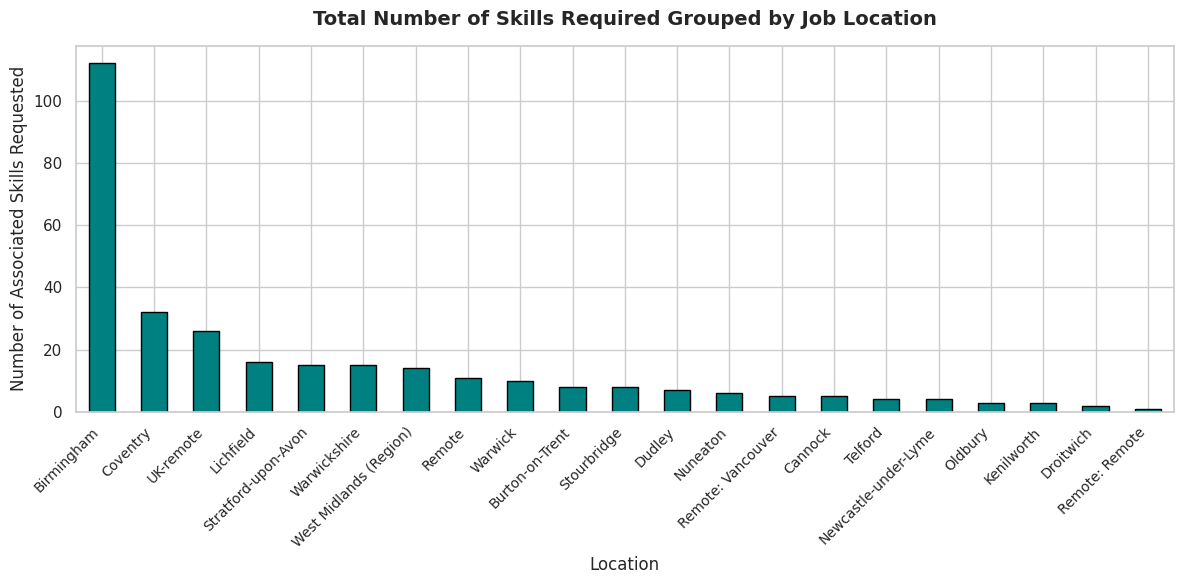

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure location_clean exists and extract location inside parentheses or clean it
skills_flat['location_clean'] = skills_flat['location_text'].fillna('Unknown Location')

# Group by the clean Location value to count the total associated skills requested in that area
location_skill_counts = skills_flat.groupby('location_clean')['skill'].count().sort_values(ascending=False)

# Set plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Plot Number of skills per Location
location_skill_counts.plot(kind='bar', color='teal', edgecolor='black')

# Customizing labels and titles
plt.title('Total Number of Skills Required Grouped by Job Location', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Number of Associated Skills Requested', fontsize=12)
plt.xlabel('Location', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)

plt.tight_layout()
plt.show()

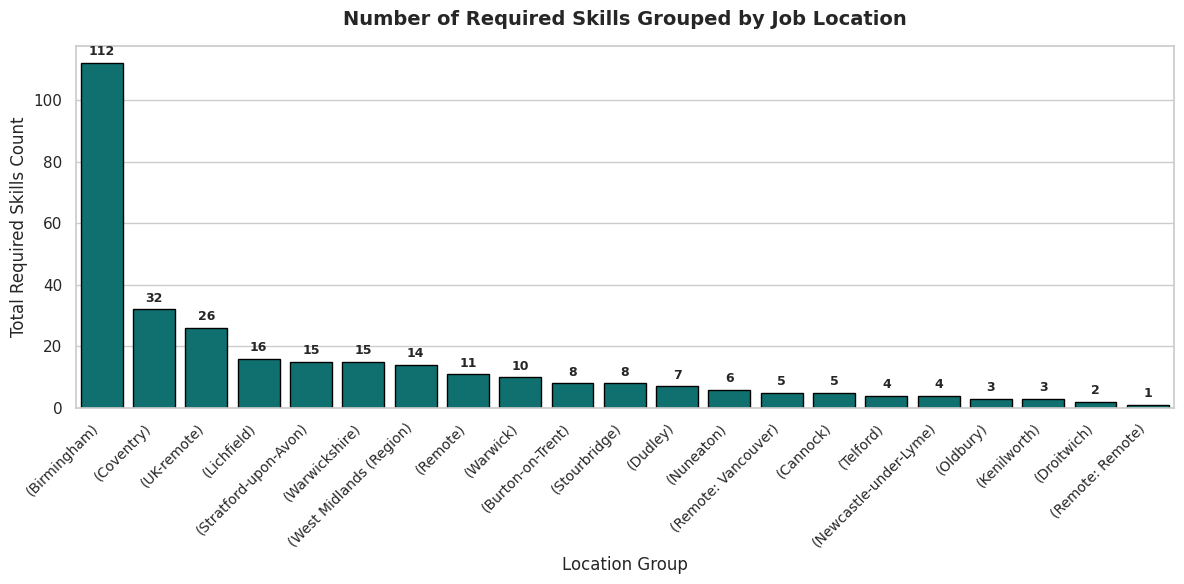

In [6]:
import re
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Reload the correct merged flat DataFrame
vacancies_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/refs/heads/data-snapshots/data/live_snapshots/20261030_1324/shown.csv'
try:
    vac_current = pd.read_csv(vacancies_url)
except Exception:
    import requests
    import io
    response = requests.get(vacancies_url)
    vac_current = pd.read_csv(io.StringIO(response.text))

skills_flat_current = pd.merge(skills, vac_current, on='vacancy_id', how='inner')

# 2. Extract base fields cleanly
skills_flat_current['employer_clean'] = skills_flat_current['employer'].fillna('Unknown Employer')
skills_flat_current['location_clean'] = skills_flat_current['location_text'].fillna('Unknown Location')
skills_flat_current['employer_location'] = skills_flat_current['employer_clean'] + ' (' + skills_flat_current['location_clean'] + ')'

# 3. Extract only the parenthesized portion
def extract_parenthesized_location(text):
    match = re.search(r'\(([^)]+)\)', str(text))
    if match:
        return f"({match.group(1)})"
    return "(Unknown Location)"

skills_flat_current['location_group'] = skills_flat_current['employer_location'].apply(extract_parenthesized_location)

# 4. Calculate total skills required per Location group
location_skills = skills_flat_current.groupby('location_group')['skill'].count().sort_values(ascending=False).reset_index()
location_skills.columns = ['Location Group', 'Skill Count']

# 5. Recreate the bar chart
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=location_skills,
    x='Location Group',
    y='Skill Count',
    color='teal',
    edgecolor='black'
)

# Annotate heights
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{int(p.get_height())}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=9, fontweight='semibold')

plt.title('Number of Required Skills Grouped by Job Location', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Location Group', fontsize=12)
plt.ylabel('Total Required Skills Count', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)

plt.tight_layout()
plt.show()

The area of the shape represents the whole of the set of skills required. the red area show the skills not included in the course.   I am querying SQL because I don't think it was taught. “That SQL module was NOT IN (SELECT topic FROM .codeinstitute_LMS).”

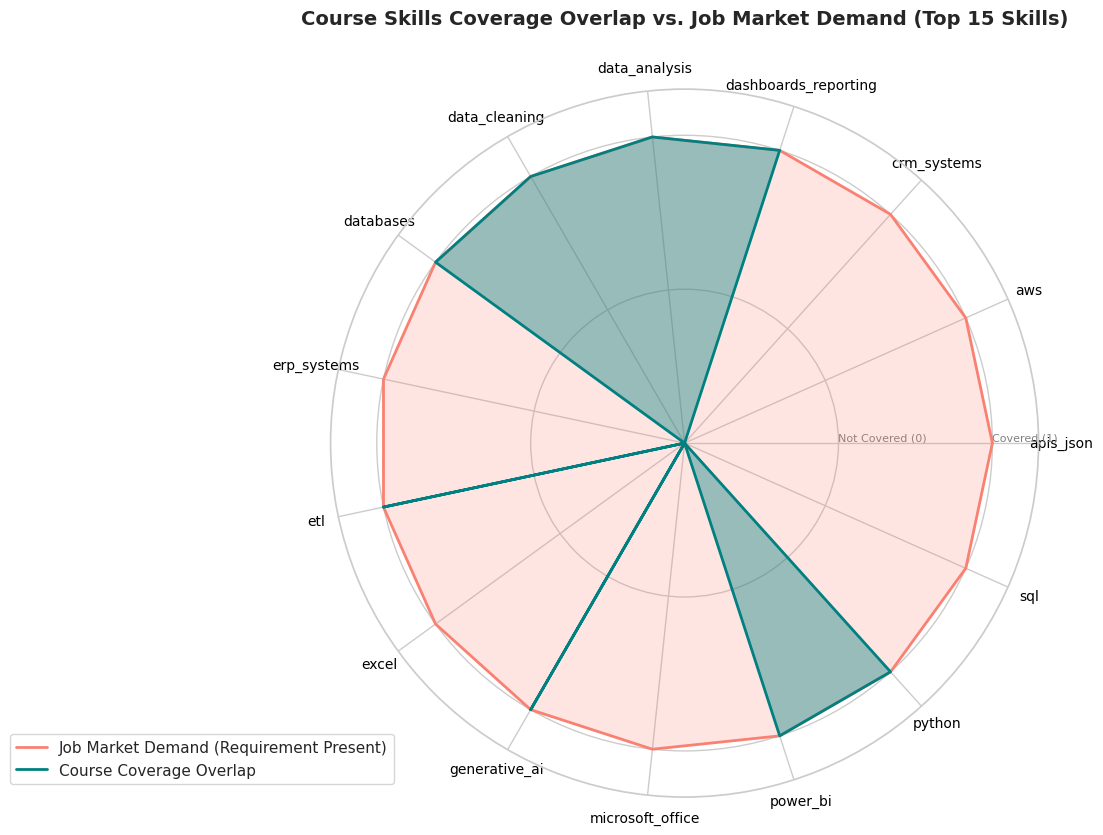

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml

# URL of the raw CSV file on GitHub
csv_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/refs/heads/data-snapshots/data/live_snapshots/20261030_1324/skills.csv'
skills = pd.read_csv(csv_url)

# 1. Load the technical skills taxonomy to get course coverage
yaml_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/refs/heads/main/prototype/app/data/taxonomy/technical_skills.yaml'
try:
    response = requests.get(yaml_url)
    response.raise_for_status()
    taxonomy_data = yaml.safe_load(response.text)

    rows = []
    skills_list = taxonomy_data.get("skills", [])
    for item in skills_list:
        rows.append({
            "id": item.get("id"),
            "course_covered": item.get("course_covered", False)
        })
    df = pd.DataFrame(rows)
except Exception as e:
    print(f"Error fetching or parsing the YAML file: {e}")
    df = pd.DataFrame(columns=['id', 'course_covered'])

# 2. Focus on top 15 skills to keep the radar chart readable
skill_counts = skills['skill'].value_counts()
top_n = 15
top_skills_list = list(skill_counts.head(top_n).index)
all_skills = sorted(top_skills_list)

# Filter df to check course coverage
covered_course_skills = set(df[df['course_covered'] == True]['id'])

# 3. Build radar chart values
# Job value is always 1 (representing a full demand boundary for every skill)
job_values = [1 for skill in all_skills]

# Course coverage value is binary (1 if covered, else 0)
course_values = [1 if skill in covered_course_skills else 0 for skill in all_skills]

# Number of variables
num_vars = len(all_skills)

# Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# Close the loop
course_values += course_values[:1]
job_values += job_values[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(11, 11), subplot_kw=dict(polar=True))

# Draw axes labels
plt.xticks(angles[:-1], all_skills, color='black', size=10, rotation=45)

# Set y-axis limits
ax.set_rlabel_position(0)
plt.yticks([0.5, 1.0], ["Not Covered (0)", "Covered (1)"], color="grey", size=8)
plt.ylim(0, 1.15)

# Plot Job Market Demand (Boundary set to 1 for all skills)
ax.plot(angles, job_values, linewidth=2, linestyle='solid', label="Job Market Demand (Requirement Present)", color='salmon')
ax.fill(angles, job_values, color='salmon', alpha=0.2)

# Plot Course Skills Covered (Binary coverage: 1 or 0)
ax.plot(angles, course_values, linewidth=2, linestyle='solid', label="Course Coverage Overlap", color='teal')
ax.fill(angles, course_values, color='teal', alpha=0.4)

# Details
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.title("Course Skills Coverage Overlap vs. Job Market Demand (Top 15 Skills)", size=14, fontweight='bold', y=1.08)

plt.tight_layout()
plt.show()

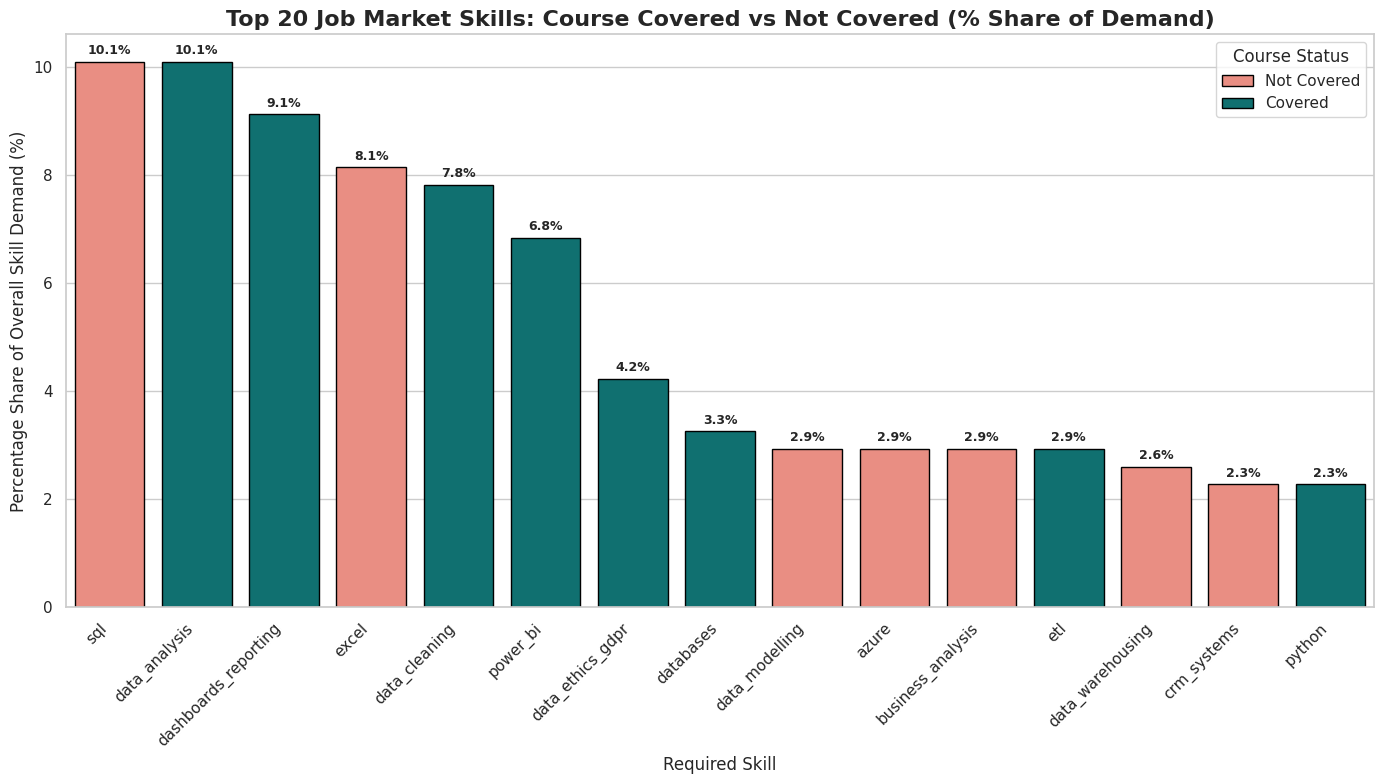

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Calculate frequency of skills in skills_flat
skill_counts = skills_flat['skill'].value_counts()
total_demand = skill_counts.sum()

# Convert to percentage share
skill_percentages = (skill_counts / total_demand) * 100

# Focus on the top 15 skills
top_n = 15
top_skills = skill_counts.head(top_n).index

# Filter taxonomy course coverage
covered_course_skills = set(df[df['course_covered'] == True]['id'])

# Build visualization dataset
plot_df = pd.DataFrame({
    'Skill': top_skills,
    'Percentage Share': [skill_percentages[skill] for skill in top_skills],
    'Course Covered': ['Covered' if skill in covered_course_skills else 'Not Covered' for skill in top_skills]
})

# Plot bar chart
plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=plot_df,
    x='Skill',
    y='Percentage Share',
    hue='Course Covered',
    palette={'Covered': 'teal', 'Not Covered': 'salmon'},
    edgecolor='black'
)

plt.title('Top 20 Job Market Skills: Course Covered vs Not Covered (% Share of Demand)', fontsize=16, fontweight='bold')
plt.xlabel('Required Skill', fontsize=12)
plt.ylabel('Percentage Share of Overall Skill Demand (%)', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.legend(title='Course Status', fontsize=11, title_fontsize=12)

# Annotate percentages on top of bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.1f}%",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=9, fontweight='semibold')

plt.tight_layout()
plt.show()

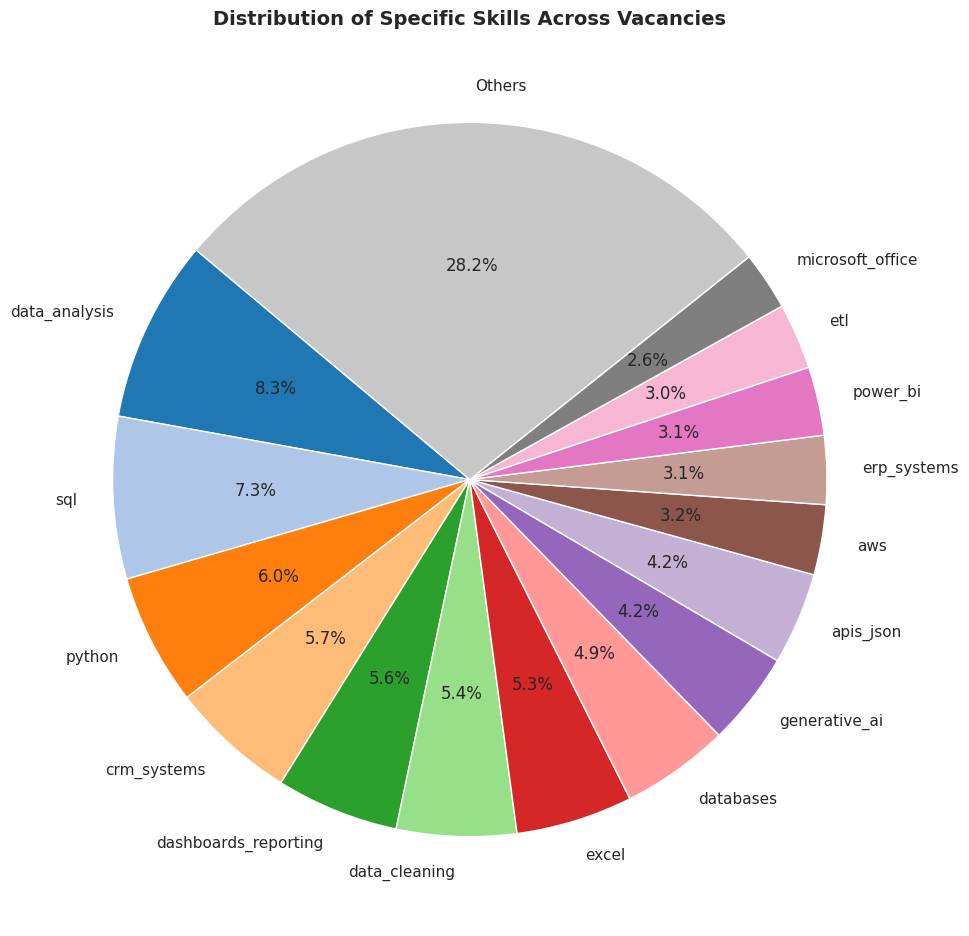

In [9]:
import matplotlib.pyplot as plt

# Count occurrences of each unique skill
skill_counts = skills['skill'].value_counts()

# To make the pie chart readable, we will show the top 10 skills and group the rest as 'Others'
top_n = 15
top_skills = skill_counts.head(top_n)
others_count = skill_counts.iloc[top_n:].sum()

# Combine top skills with 'Others'
plot_data = top_skills.copy()
if others_count > 0:
    plot_data['Others'] = others_count

# Create the pie chart
plt.figure(figsize=(10, 10))
plt.pie(
    plot_data,
    labels=plot_data.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=plt.cm.tab20.colors[:len(plot_data)]
)

plt.title('Distribution of Specific Skills Across Vacancies', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Loaded shown.csv successfully!


/tmp/ipykernel_22290/4114946049.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_locations.values, y=top_locations.index, ax=axes[0], palette="viridis")
/tmp/ipykernel_22290/4114946049.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_titles.values, y=top_titles.index, ax=axes[1], palette="magma")


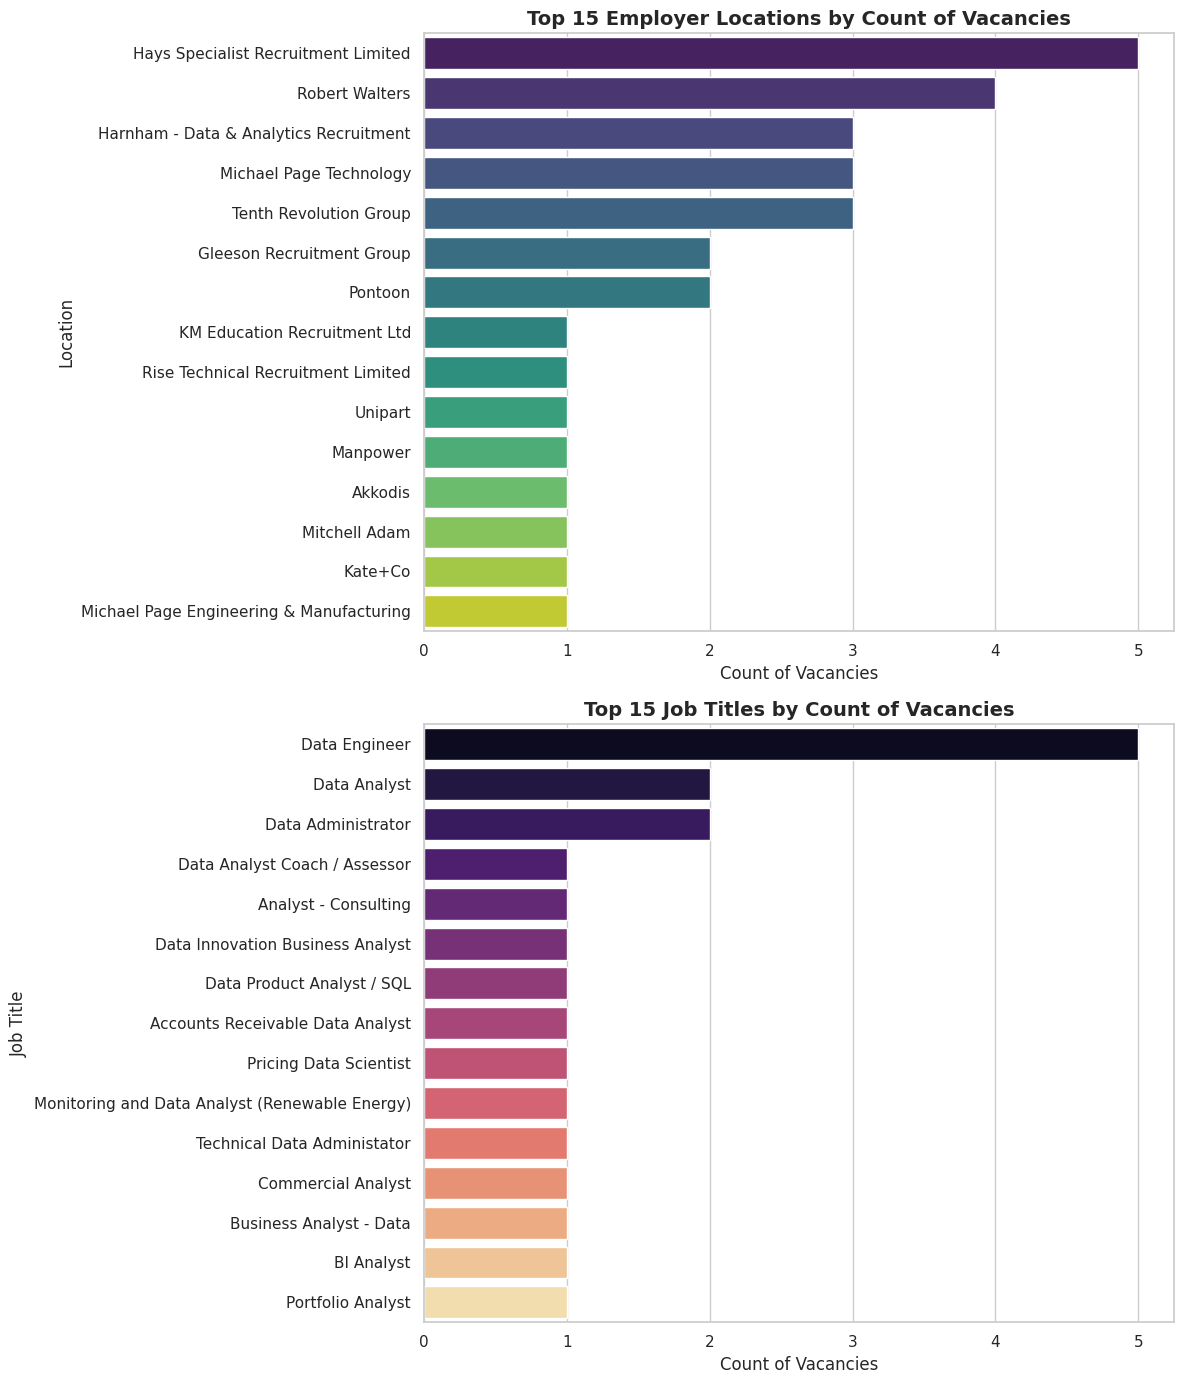

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert GitHub URL to Raw URL
shown_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/data-snapshots/data/live_snapshots/20261030_1324/shown.csv'

# Load the shown.csv dataset
try:
    shown_df = pd.read_csv(shown_url)
    print("Loaded shown.csv successfully!")
except Exception as e:
    import requests
    import io
    response = requests.get(shown_url)
    shown_df = pd.read_csv(io.StringIO(response.text))
    print("Loaded shown.csv via requests fallback.")

# Set seaborn theme
sns.set_theme(style="whitegrid")

# Set up matplotlib subplots
fig, axes = plt.subplots(2, 1, figsize=(12, 14))

# 1. Plot Employer Location counts
# Check the columns in the DataFrame to find exact matches for location and title
loc_col = [c for c in shown_df.columns if 'location' in c.lower() or 'employer' in c.lower()]
title_col = [c for c in shown_df.columns if 'title' in c.lower()]

# Use matched columns or fallback defaults
loc_column = loc_col[0] if loc_col else 'employer_text_location'
title_column = title_col[0] if title_col else 'title'

# Plot top employer locations
top_locations = shown_df[loc_column].value_counts().head(15)
sns.barplot(x=top_locations.values, y=top_locations.index, ax=axes[0], palette="viridis")
axes[0].set_title('Top 15 Employer Locations by Count of Vacancies', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Count of Vacancies', fontsize=12)
axes[0].set_ylabel('Location', fontsize=12)

# Plot top job titles
top_titles = shown_df[title_column].value_counts().head(15)
sns.barplot(x=top_titles.values, y=top_titles.index, ax=axes[1], palette="magma")
axes[1].set_title('Top 15 Job Titles by Count of Vacancies', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Count of Vacancies', fontsize=12)
axes[1].set_ylabel('Job Title', fontsize=12)

plt.tight_layout()
plt.show()

In [11]:
import requests
import yaml
import pandas as pd

# Convert GitHub blob URL to raw URL
yaml_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/refs/heads/main/prototype/app/data/taxonomy/technical_skills.yaml'

try:
    response = requests.get(yaml_url)
    response.raise_for_status()
    data = yaml.safe_load(response.text)

    # Extract only the fields we want from the 'skills' key
    rows = []
    skills_list = data.get("skills", [])

    for item in skills_list:
        rows.append({
            "id": item.get("id"),
            "course_covered": item.get("course_covered")
        })

    df = pd.DataFrame(rows)
    display(df.head())
except Exception as e:
    print(f"Error fetching or parsing the YAML file: {e}")

,id,course_covered
0,python,True
1,pandas,True
2,numpy,True
3,r_language,False
4,vba,False


In [12]:
skills['skill'].head()

,skill
0,crm_systems
1,excel
2,data_analysis
3,data_cleaning
4,erp_systems


In [13]:
job_skills = set(skills['skill'].unique())
job_skills
skill_counts = skills['skill'].value_counts()
skill_counts

,count
skill,
data_analysis,125
sql,111
python,90
crm_systems,86
dashboards_reporting,84
data_cleaning,82
excel,80
databases,74
generative_ai,64


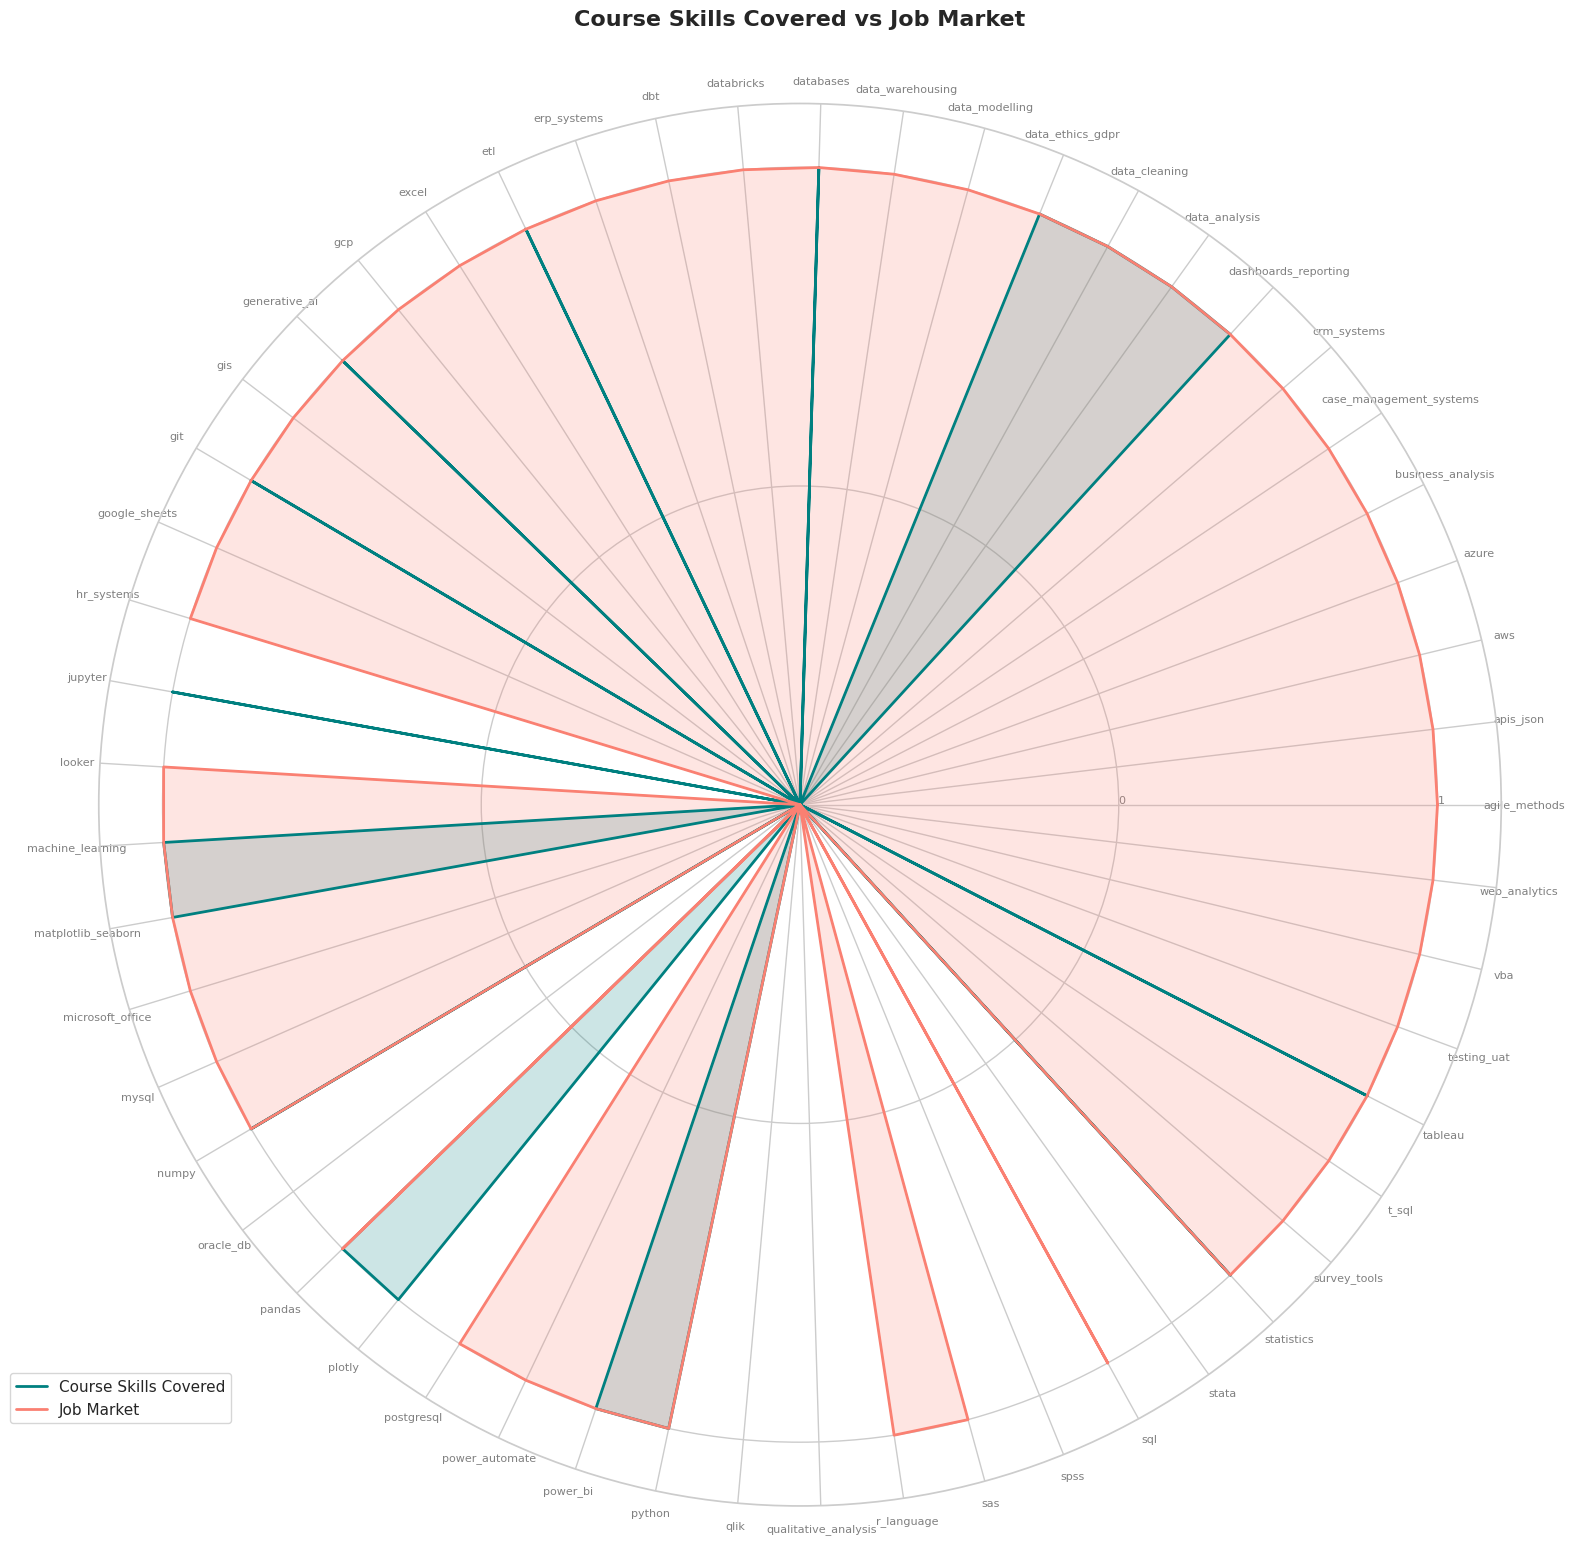

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Align skills
# Extract unique skills from both data sources
course_skills = set(df['id'].unique())
job_skills = set(skills['skill'].unique())

# Get the union of all skills
all_skills = sorted(list(course_skills.union(job_skills)))

# Filter df to quickly check coverage
covered_course_skills = set(df[df['course_covered'] == True]['id'])

# 2. Build radar chart data
course_values = [1 if skill in covered_course_skills else 0 for skill in all_skills]
job_values = [1 if skill in job_skills else 0 for skill in all_skills]

# 3. Plot radar chart
# Number of variables
num_vars = len(all_skills)

# Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# The radar chart needs to close the loop, so append the start value to the end
course_values += course_values[:1]
job_values += job_values[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(16, 16), subplot_kw=dict(polar=True))

# Draw one axe per variable and add labels
plt.xticks(angles[:-1], all_skills, color='grey', size=8, rotation=45)

# Draw ylabels
ax.set_rlabel_position(0)
plt.yticks([0.5, 1.0], ["0", "1"], color="grey", size=8)
plt.ylim(0, 1.1)

# Plot Course Skills Covered
ax.plot(angles, course_values, linewidth=2, linestyle='solid', label="Course Skills Covered", color='teal')
ax.fill(angles, course_values, color='teal', alpha=0.2)

# Plot Job Market
ax.plot(angles, job_values, linewidth=2, linestyle='solid', label="Job Market", color='salmon')
ax.fill(angles, job_values, color='salmon', alpha=0.2)

# Add Legend and Title
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.title("Course Skills Covered vs Job Market", size=16, fontweight='bold', y=1.05)

plt.tight_layout()
plt.show()

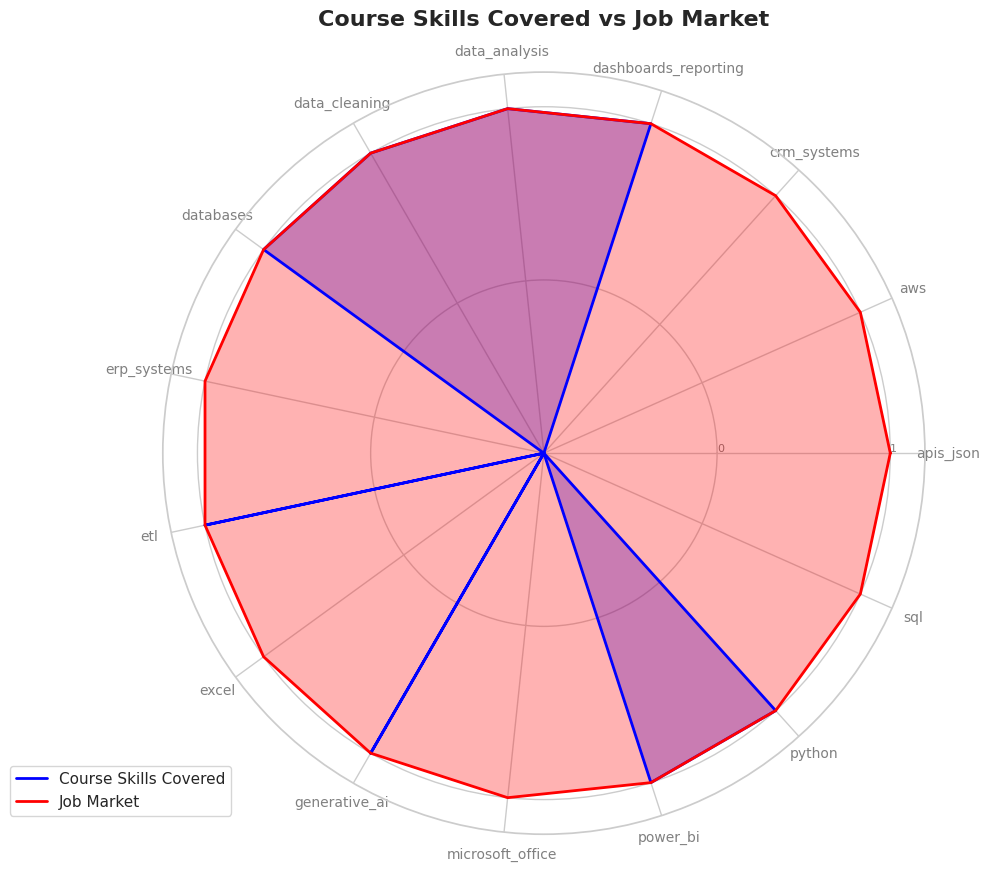

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Define top N limit for skills to keep the radar chart readable
top_n = 15

# Get top skills based on frequency in the job market
top_job_skills = list(skills['skill'].value_counts().head(top_n).index)

# Align skills focusing only on the top job market skills
all_skills = sorted(top_job_skills)

# Filter df to check course coverage
covered_course_skills = set(df[df['course_covered'] == True]['id'])

# Build radar chart data for these filtered skills
course_values = [1 if skill in covered_course_skills else 0 for skill in all_skills]
job_values = [1 if skill in top_job_skills else 0 for skill in all_skills]

# Number of variables
num_vars = len(all_skills)

# Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# Close the loop
course_values += course_values[:1]
job_values += job_values[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

# Draw axes
plt.xticks(angles[:-1], all_skills, color='grey', size=10, rotation=45)

# Draw y-axis labels
ax.set_rlabel_position(0)
plt.yticks([0.5, 1.0], ["0", "1"], color="grey", size=8)
plt.ylim(0, 1.1)

# Plot datasets
ax.plot(angles, course_values, linewidth=2, linestyle='solid', label="Course Skills Covered", color='blue')
ax.fill(angles, course_values, color='blue', alpha=0.3)

ax.plot(angles, job_values, linewidth=2, linestyle='solid', label="Job Market", color='red')
ax.fill(angles, job_values, color='red', alpha=0.3)

# Details
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.title("Course Skills Covered vs Job Market", size=16, fontweight='bold', y=1.05)

plt.tight_layout()
plt.show()

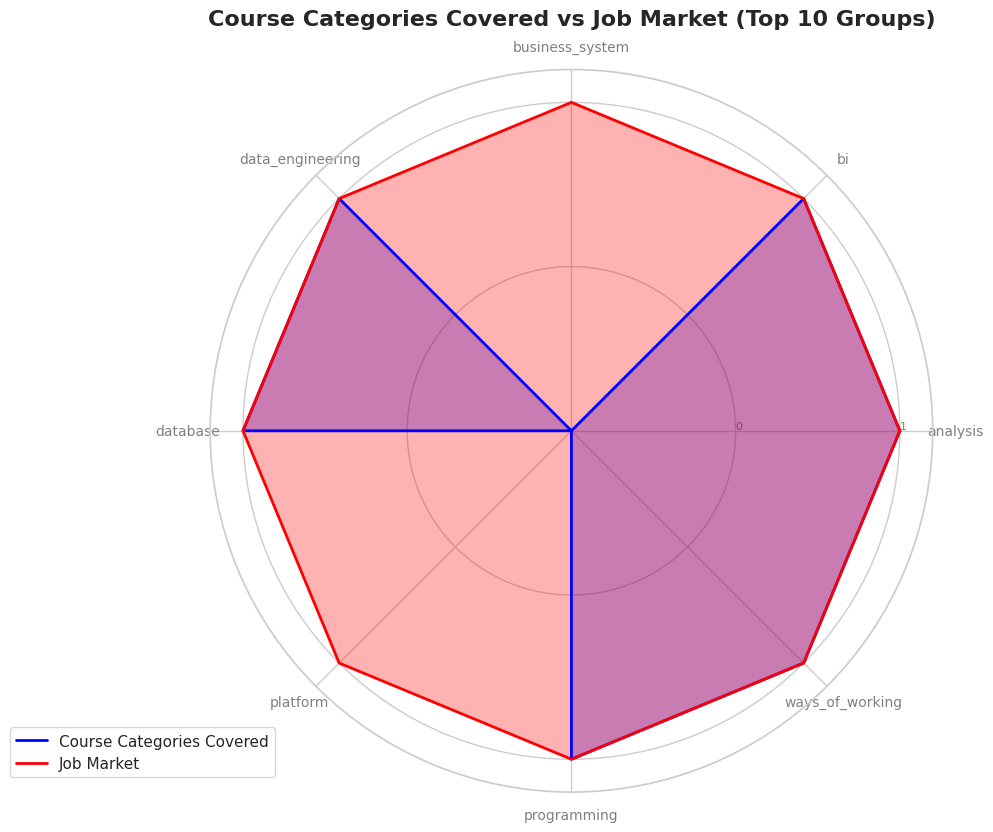

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Map each skill 'id' to its 'category' from the original technical skills dataset
# Re-extract the category field from the YAML dataset first
rows_with_categories = []
skills_list = data.get("skills", [])
for item in skills_list:
    rows_with_categories.append({
        "id": item.get("id"),
        "category": item.get("category"),
        "course_covered": item.get("course_covered", False)
    })
category_df = pd.DataFrame(rows_with_categories)

# Create a dictionary for mapping skill id -> category
skill_to_cat = dict(zip(category_df['id'], category_df['category']))

# Map skills in our job market data to their categories
skills_mapped = skills.copy()
skills_mapped['category'] = skills_mapped['skill'].map(skill_to_cat)

# Drop rows where category is not found in taxonomy
skills_mapped = skills_mapped.dropna(subset=['category'])

# 2. Get the top 10 categories based on job market demand
top_n_categories = 8
top_cats = list(skills_mapped['category'].value_counts().head(top_n_categories).index)
all_categories = sorted(top_cats)

# 3. Calculate category coverage and demand
# - Course Category Covered: 1 if ANY skill in that category is covered in the course, else 0
covered_cats = set(category_df[category_df['course_covered'] == True]['category'])
course_values = [1 if cat in covered_cats else 0 for cat in all_categories]

# - Job Market Category: 1 if the category is present in the top job categories, else 0
job_values = [1 if cat in top_cats else 0 for cat in all_categories]

# 4. Plot radar chart
num_vars = len(all_categories)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# Close the loop
course_values += course_values[:1]
job_values += job_values[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

# Draw axes labels
plt.xticks(angles[:-1], all_categories, color='grey', size=10, rotation=45)

# Draw y-axis labels
ax.set_rlabel_position(0)
plt.yticks([0.5, 1.0], ["0", "1"], color="grey", size=8)
plt.ylim(0, 1.1)

# Plot datasets
ax.plot(angles, course_values, linewidth=2, linestyle='solid', label="Course Categories Covered", color='blue')
ax.fill(angles, course_values, color='blue', alpha=0.3)

ax.plot(angles, job_values, linewidth=2, linestyle='solid', label="Job Market", color='red')
ax.fill(angles, job_values, color='red', alpha=0.3)

# Labels and Legend
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.title("Course Categories Covered vs Job Market (Top 10 Groups)", size=16, fontweight='bold', y=1.05)

plt.tight_layout()
plt.show()

In [17]:
import io
import pandas as pd
import requests
import yaml

# URLs from the workbook
csv_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/data-snapshots/data/live_snapshots/20261030_1324/skills.csv'
yaml_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/refs/heads/main/prototype/app/data/taxonomy/technical_skills.yaml'

# 1. Fresh load of the skills DataFrame
response_csv = requests.get(csv_url)
skills_fresh = pd.read_csv(io.StringIO(response_csv.text))

# 2. Get the top 25 skills and their counts
top_25_counts = skills_fresh['skill'].value_counts().head(25).reset_index()
top_25_counts.columns = ['skill', 'count']

# 3. Fresh load of the taxonomy to get course coverage
response_yaml = requests.get(yaml_url)
taxonomy_data = yaml.safe_load(response_yaml.text)

rows = []
for item in taxonomy_data.get("skills", []):
    rows.append({
        "skill": item.get("id"),
        "course_covered": item.get("course_covered", False)
    })
taxonomy_df = pd.DataFrame(rows)

# 4. Combine top 25 skills with course coverage
combined_df = pd.merge(top_25_counts, taxonomy_df, on='skill', how='left')

# Display the top rows
combined_df.head(25)

,skill,count,course_covered
0,data_analysis,125,True
1,sql,111,False
2,python,90,True
3,crm_systems,86,False
4,dashboards_reporting,84,True
5,data_cleaning,82,True
6,excel,80,False
7,databases,74,True
8,generative_ai,64,True
9,apis_json,63,False


In [23]:

import pandas as pd

vacancies_history_url = 'https://raw.githubusercontent.com/TidyWeb/SkillMatch/refs/heads/data-snapshots/data/live_snapshots/history/adverts_history.csv'

try:
    vacancies = pd.read_csv(vacancies_history_url)
    print("Vacancies DataFrame loaded successfully!")
except Exception as e:
    import requests
    import io
    print(f"Error loading via pandas directly: {e}. Trying fallback with requests...")
    response = requests.get(vacancies_history_url)
    vacancies = pd.read_csv(io.StringIO(response.text))

# Join the two DataFrames on 'vacancy_id'
skills_flat = pd.merge(skills, vacancies, on='vacancy_id', how='inner')

print(f"Skills shape: {skills.shape}")
print(f"Vacancies shape: {vacancies.shape}")
print(f"Merged flat DataFrame shape: {skills_flat.shape}")
display(skills_flat.head())


Vacancies DataFrame loaded successfully!
Skills shape: (1512, 6)
Vacancies shape: (7242, 6)
Merged flat DataFrame shape: (1512, 11)


,run_id,vacancy_id,skill,strength,confidence,description_coverage,first_seen,last_seen,times_seen,latest_outcome,sources_seen
0,20261030T131438880602Z,greenhouse:gymshark-4863068101,crm_systems,desirable,stated,full,2026-10-27T12:55:36Z,2026-10-30T13:22:50Z,7,senior,greenhouse
1,20261030T131438880602Z,greenhouse:gymshark-4958803101,excel,essential,stated,full,2026-10-27T12:55:36Z,2026-10-30T13:22:50Z,7,senior,greenhouse
2,20261030T131438880602Z,greenhouse:gymshark-4959277101,data_analysis,essential,stated,full,2026-10-21T20:32:24Z,2026-10-30T13:22:50Z,8,not a data role,greenhouse
3,20261030T131438880602Z,greenhouse:gymshark-4959277101,data_cleaning,unclear,stated,full,2026-10-21T20:32:24Z,2026-10-30T13:22:50Z,8,not a data role,greenhouse
4,20261030T131438880602Z,greenhouse:gymshark-4959277101,erp_systems,desirable,stated,full,2026-10-21T20:32:24Z,2026-10-30T13:22:50Z,8,not a data role,greenhouse


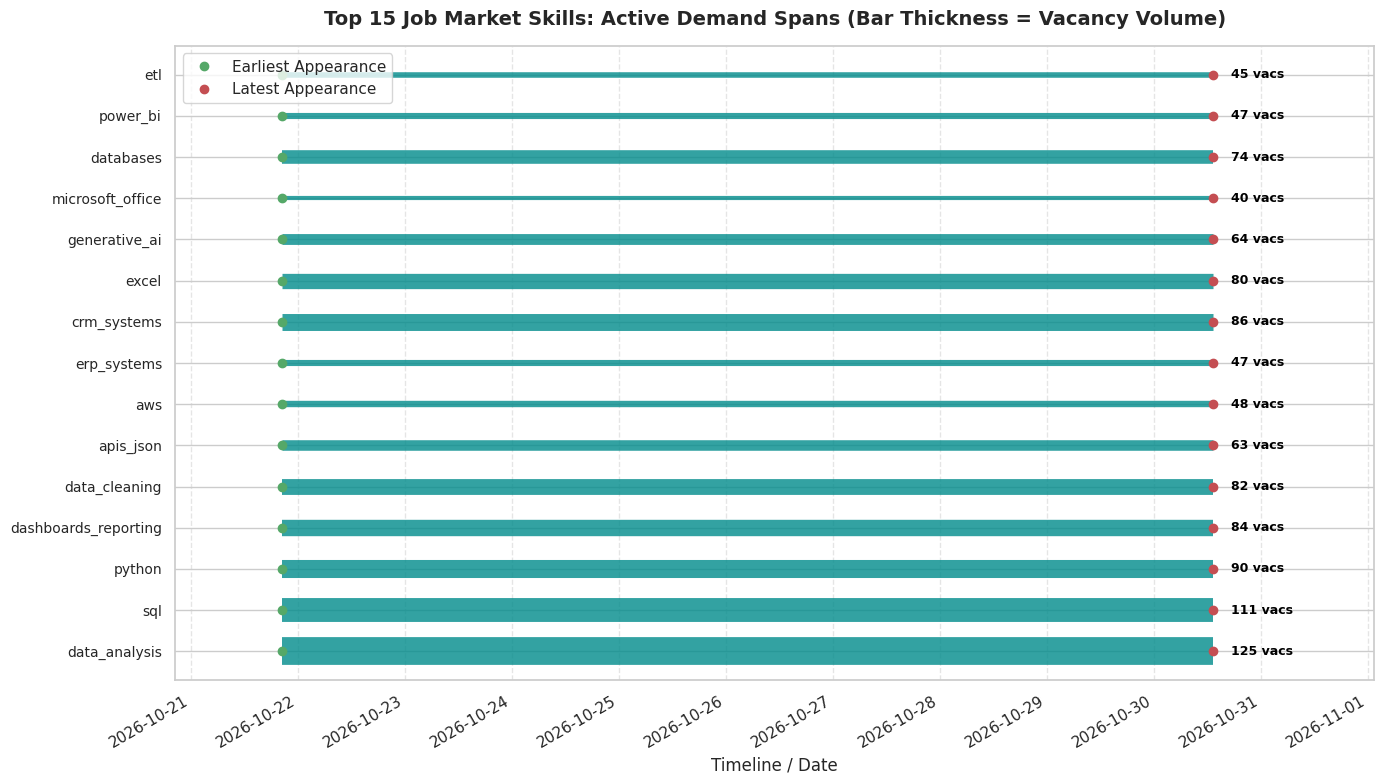

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

# 1. Copy and convert date columns to datetime
df_timeline = skills_flat.copy()
df_timeline['first_seen'] = pd.to_datetime(df_timeline['first_seen'])
df_timeline['last_seen'] = pd.to_datetime(df_timeline['last_seen'])

# Group by 'skill' to find active dates and count unique vacancy occurrences
skills_timeline = df_timeline.groupby('skill').agg(
    first_seen=('first_seen', 'min'),
    last_seen=('last_seen', 'max'),
    occurrences=('vacancy_id', 'nunique')
).reset_index()

# Filter to focus only on the top 15 skills by unique vacancy occurrences
skills_timeline = skills_timeline.nlargest(15, 'occurrences')

# Sort skills by their earliest appearance date to keep structural flow in the timeline
skills_timeline = skills_timeline.sort_values(by='first_seen', ascending=True).reset_index(drop=True)

# Normalize vacancy occurrences to set a logical proportional bar height (linewidth)
min_width, max_width = 3, 20
min_occ, max_occ = skills_timeline['occurrences'].min(), skills_timeline['occurrences'].max()

if max_occ > min_occ:
    skills_timeline['bar_width'] = min_width + (max_width - min_width) * (skills_timeline['occurrences'] - min_occ) / (max_occ - min_occ)
else:
    skills_timeline['bar_width'] = 8

# 2. Plot the Timeline blocks per Skill with heights proportional to demand volume
plt.figure(figsize=(14, 8))
y_positions = np.arange(len(skills_timeline))

# Plot horizontal bars with custom heights (linewidths) per skill
for i, row in skills_timeline.iterrows():
    plt.hlines(
        y=i,
        xmin=row['first_seen'],
        xmax=row['last_seen'],
        colors='darkcyan',
        linewidth=row['bar_width'],
        alpha=0.8
    )
    # Annotate vacancy count at the end of each bar
    plt.text(
        row['last_seen'] + pd.Timedelta(hours=4),
        i,
        f"{row['occurrences']} vacs",
        va='center',
        ha='left',
        fontsize=9,
        fontweight='bold',
        color='black'
    )

# Plot key points
plt.plot(skills_timeline['first_seen'], y_positions, 'go', markersize=6, label='Earliest Appearance')
plt.plot(skills_timeline['last_seen'], y_positions, 'ro', markersize=6, label='Latest Appearance')

# Adjust formatting
plt.yticks(y_positions, skills_timeline['skill'], fontsize=10)
plt.xlabel('Timeline / Date', fontsize=12)
plt.title('Top 15 Job Market Skills: Active Demand Spans (Bar Thickness = Vacancy Volume)', fontsize=14, fontweight='bold', pad=15)

# Format date ticks on x-axis
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=1))
plt.gcf().autofmt_xdate()

# Set limits to make room for annotations
plt.xlim(skills_timeline['first_seen'].min() - pd.Timedelta(days=1), skills_timeline['last_seen'].max() + pd.Timedelta(days=1.5))

plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

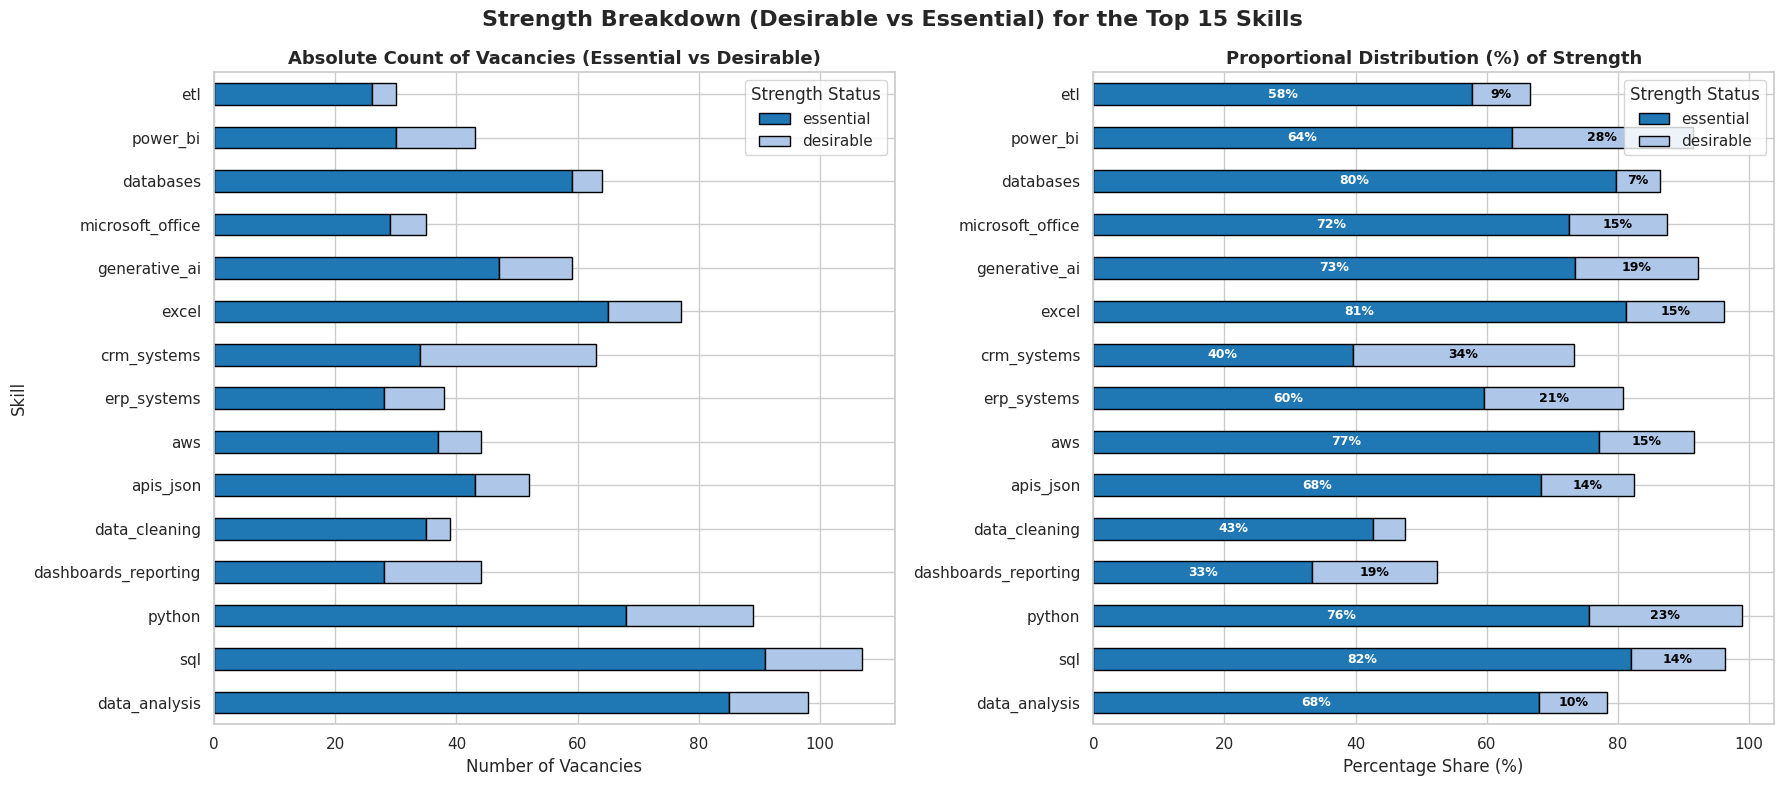

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Identify the top 15 skills from the timeline dataset
top_15_skills = skills_timeline['skill'].tolist()

# 2. Filter our flat dataset to only contain these top 15 skills
df_top15_strength = skills_flat[skills_flat['skill'].isin(top_15_skills)].copy()

# 3. Create a crosstabulation of skill and strength
strength_counts = pd.crosstab(df_top15_strength['skill'], df_top15_strength['strength']).reindex(top_15_skills)

# Ensure strength categories 'essential' and 'desirable' exist in our columns (fill missing with 0)
for col in ['essential', 'desirable']:
    if col not in strength_counts.columns:
        strength_counts[col] = 0

# Calculate percentages for normalized viewing
strength_pct = strength_counts.div(strength_counts.sum(axis=1), axis=0) * 100

# 4. Plot side-by-side or stacked bar charts to compare counts and proportions
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
sns.set_theme(style="whitegrid")

# Plot 1: Absolute Counts of Essential vs Desirable
strength_counts[['essential', 'desirable']].plot(
    kind='barh',
    stacked=True,
    ax=axes[0],
    color=['#1f77b4', '#aec7e8'],
    edgecolor='black'
)
axes[0].set_title('Absolute Count of Vacancies (Essential vs Desirable)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Vacancies')
axes[0].set_ylabel('Skill')
axes[0].legend(title='Strength Status')

# Plot 2: Relative Proportions (%)
strength_pct[['essential', 'desirable']].plot(
    kind='barh',
    stacked=True,
    ax=axes[1],
    color=['#1f77b4', '#aec7e8'],
    edgecolor='black'
)
axes[1].set_title('Proportional Distribution (%) of Strength', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Percentage Share (%)')
axes[1].set_ylabel('')
axes[1].legend(title='Strength Status')

# Annotate percentages inside the bars of the second plot
for i, (idx, row) in enumerate(strength_pct.iterrows()):
    essential_val = row['essential']
    if essential_val > 5:
        axes[1].text(essential_val / 2, i, f"{essential_val:.0f}%", va='center', ha='center', color='white', fontweight='bold', fontsize=9)
    desirable_val = row['desirable']
    if desirable_val > 5:
        axes[1].text(essential_val + (desirable_val / 2), i, f"{desirable_val:.0f}%", va='center', ha='center', color='black', fontweight='bold', fontsize=9)

plt.suptitle('Strength Breakdown (Desirable vs Essential) for the Top 15 Skills', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()